# Spotify Music Recommendation System

**Final project notebook**  
**Anil Bammidi | DSC680 Applied Data Science | Bellevue University**

This notebook implements and evaluates two methods supported by the available Spotify track data:

1. a popularity baseline for cold-start recommendations, and
2. a content-based K-nearest-neighbors model using scaled audio features and cosine distance.

The dataset does not contain real user-item interactions. For that reason, this final version does not report simulated SVD or hybrid RMSE values.


## Research objective

The project asks whether a simple layered design can provide useful cold-start recommendations and meaningful track discovery from catalog metadata. The empirical analysis focuses only on methods that are actually fitted in this notebook. Collaborative filtering remains future work that requires consented listening histories, a documented holdout design, and real user-level evaluation.


## Environment setup and data preparation

The workflow loads `Spotify_dataset.csv`, removes duplicate track identifiers, removes records without a track name or artist, and resets the DataFrame index. Resetting the index keeps DataFrame rows aligned with the scaled feature matrix used by KNN.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors



<frozen importlib._bootstrap>:219: RuntimeWarning: scipy._lib.messagestream.MessageStream size changed, may indicate binary incompatibility. Expected 56 from C header, got 64 from PyObject


In [2]:
# Set the notebook to show plots inline

%matplotlib inline
# Set a consistent style
sns.set(style="whitegrid")

# 1. LOAD AND PREPROCESS THE Spotify dataset
df = pd.read_csv('Spotify_dataset.csv')
df = df.drop_duplicates(subset='track_id')
df = df.dropna(subset=['track_name', 'artists']).reset_index(drop=True)
print(f"Dataset initialized with {df.shape[0]} unique tracks.")


Dataset initialized with 89740 unique tracks.


__Exploratory Data Analysis (EDA)__

Before building the models, we must understand the "texture" of the data.

__A. Demographic Insight__: Popularity Distribution
The popularity distribution reveals a "Long Tail" effect. Most songs have low popularity scores, meaning a simple "Top 40" recommender would ignore the vast majority of the library.

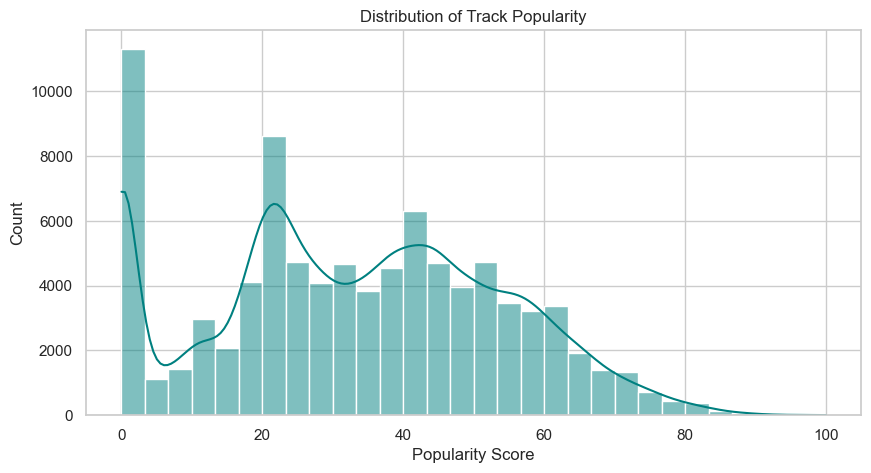

In [3]:
# ---------------------------------------------------------
# VISUALIZATIONS (Exploratory Data Analysis)
# ---------------------------------------------------------

# Graph 1: Popularity Distribution (Demographic Analysis)

plt.figure(figsize=(10, 5))
sns.histplot(df['popularity'], bins=30, kde=True, color='teal')
plt.title('Distribution of Track Popularity')
plt.xlabel('Popularity Score')
plt.show()



__B. Content Analysis:__ Audio Feature Correlation

The heatmap identifies how audio attributes relate to one another. For instance, Energy and Loudness show a strong correlation (0.76), indicating that "energetic" songs are almost always "loud."

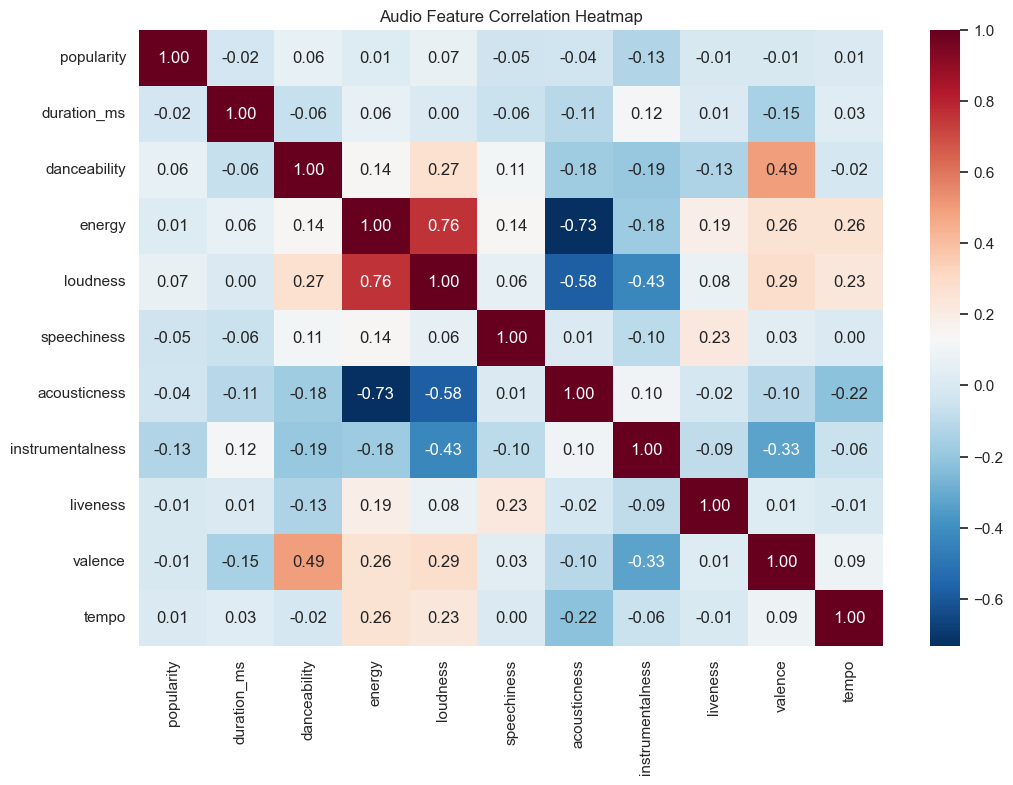

In [4]:
# Graph 2: Feature Correlation Heatmap (Content Analysis)

plt.figure(figsize=(12, 8))
numeric_cols = ['popularity', 'duration_ms', 'danceability', 'energy', 'loudness', 
                'speechiness', 'acousticness', 'instrumentalness', 'liveness', 
                'valence', 'tempo']

sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='RdBu_r', fmt=".2f")
plt.title('Audio Feature Correlation Heatmap')
plt.show()





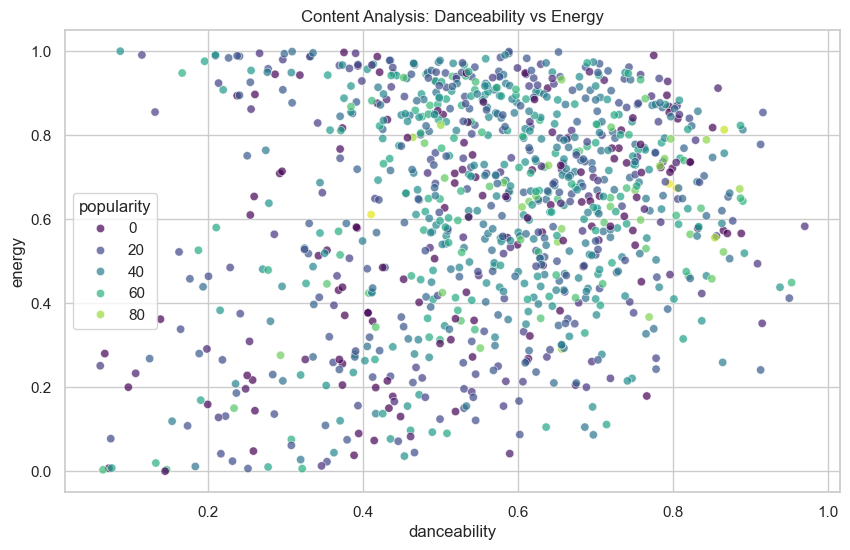

In [5]:
# Graph 3: Danceability vs Energy (Scatter Plot)
plt.figure(figsize=(10, 6))


# Sample 1000 tracks for better visibility
sns.scatterplot(data=df.sample(1000, random_state=42), x='danceability', y='energy', 
                hue='popularity', palette='viridis', alpha=0.7)
plt.title('Content Analysis: Danceability vs Energy')
plt.show()


## Model 1 Popularity baseline

The baseline sorts tracks by the observed popularity field and returns the highest-ranked records. It works without a user profile, which makes it useful for cold start. Its main limitation is popularity bias: repeated use can concentrate exposure among already prominent tracks.


In [6]:
# ---------------------------------------------------------
# RECOMMENDATION LAYERS
# ---------------------------------------------------------

# A. Demographic Filtering (Top Trending)
def get_demographic_recommendations(n=10):
    return df.sort_values('popularity', ascending=False)[['track_name', 'artists', 'popularity']].head(n)

# B. Content-Based Filtering (Nearest Neighbors)
features = ['danceability', 'energy', 'key', 'loudness', 'speechiness', 'acousticness', 
            'instrumentalness', 'liveness', 'valence', 'tempo']
scaler = MinMaxScaler()
df_features_scaled = scaler.fit_transform(df[features])

model_knn = NearestNeighbors(metric='cosine', algorithm='brute')
model_knn.fit(df_features_scaled)
# ---------------------------------------------------------
# EXECUTION & DISPLAY FOR DEMOGRAPHY RECOMMENDATION
# ---------------------------------------------------------

print("--- Demographic Recommendations (Top 5) ---")
display(get_demographic_recommendations(5))



--- Demographic Recommendations (Top 5) ---


,track_name,artists,popularity
18906,Unholy (feat. Kim Petras),Sam Smith;Kim Petras,100
45781,"Quevedo: Bzrp Music Sessions, Vol. 52",Bizarrap;Quevedo,99
18913,I'm Good (Blue),David Guetta;Bebe Rexha,98
57108,La Bachata,Manuel Turizo,98
57110,Me Porto Bonito,Bad Bunny;Chencho Corleone,97


## Model 2 Content based KNN

The content model represents each track with ten audio features. `MinMaxScaler` places the features on a common zero-to-one range, and `NearestNeighbors` retrieves nearby tracks using cosine distance. The method is interpretable and does not require user histories, but acoustic similarity does not prove that an individual listener will prefer a recommendation.


In [7]:
# Feature selection for the 'Acoustic DNA'

features = ['danceability', 'energy', 'key', 'loudness', 'speechiness', 'acousticness', 
            'instrumentalness', 'liveness', 'valence', 'tempo']

scaler = MinMaxScaler()
df_features_scaled = scaler.fit_transform(df[features])

# Initialize KNN model
model_knn = NearestNeighbors(metric='cosine', algorithm='brute')
model_knn.fit(df_features_scaled)


def get_content_recommendations(track_name, n=5):
    try:
        # Match track name
        match = df[df['track_name'].str.contains(track_name, case=False, na=False)]
        if match.empty: return "Track not found."
        
        idx = match.index[0]
        distances, indices = model_knn.kneighbors(df_features_scaled[idx].reshape(1, -1), n_neighbors=n+1)
        
        rec_indices = indices.flatten()[1:]
        return df.iloc[rec_indices][['track_name', 'artists', 'track_genre']]
    except Exception as e:
        return f"Error: {e}"


In [8]:
# ---------------------------------------------------------
# EXECUTION & DISPLAY
# ---------------------------------------------------------


print("\n--- Content-Based Recommendations for 'Comedy' ---")
display(get_content_recommendations('Comedy', 5))


--- Content-Based Recommendations for 'Comedy' ---


,track_name,artists,track_genre
9640,Sometimes,Ed Solo;Skool Of Thought;Bukue One;Pimpernal J...,breakbeat
67863,JAMAICA,Feid;Sech,pop
87901,Skylight,Gramatik,trip-hop
357,Look For The Good (Single Version),Jason Mraz,acoustic
81434,En El Coche,Aitana,spanish


## Empirical KNN diagnostics

The following diagnostics evaluate the fitted KNN retrieval process without inventing ratings. A fixed sample of query tracks measures neighbor distance, catalog coverage within the sampled neighborhoods, and average genre variety. These diagnostics describe retrieval behavior; they are not substitutes for relevance judgments from real listeners.


In [9]:
from collections import Counter

def evaluate_knn_retrieval(sample_size=250, neighbors=5, random_state=42):
    sample_size = min(sample_size, len(df))
    rng = np.random.default_rng(random_state)
    query_positions = rng.choice(len(df), size=sample_size, replace=False)

    retrieved_positions = []
    mean_distances = []
    genre_counts = []

    for position in query_positions:
        distances, indices = model_knn.kneighbors(
            df_features_scaled[position].reshape(1, -1),
            n_neighbors=neighbors + 1,
        )
        neighbor_positions = indices.flatten()[1:]
        neighbor_distances = distances.flatten()[1:]
        retrieved_positions.extend(neighbor_positions.tolist())
        mean_distances.append(float(neighbor_distances.mean()))
        genre_counts.append(int(df.iloc[neighbor_positions]['track_genre'].nunique()))

    return pd.Series({
        'queries_evaluated': sample_size,
        'neighbors_per_query': neighbors,
        'mean_cosine_distance': np.mean(mean_distances),
        'median_cosine_distance': np.median(mean_distances),
        'unique_tracks_retrieved': len(set(retrieved_positions)),
        'sampled_neighborhood_coverage': len(set(retrieved_positions)) / len(df),
        'mean_unique_genres_per_neighborhood': np.mean(genre_counts),
    })

knn_diagnostics = evaluate_knn_retrieval()
display(knn_diagnostics.to_frame('value'))


,value
queries_evaluated,250.000000
neighbors_per_query,5.000000
mean_cosine_distance,0.004172
median_cosine_distance,0.002990
unique_tracks_retrieved,1246.000000
sampled_neighborhood_coverage,0.013885
mean_unique_genres_per_neighborhood,3.988000


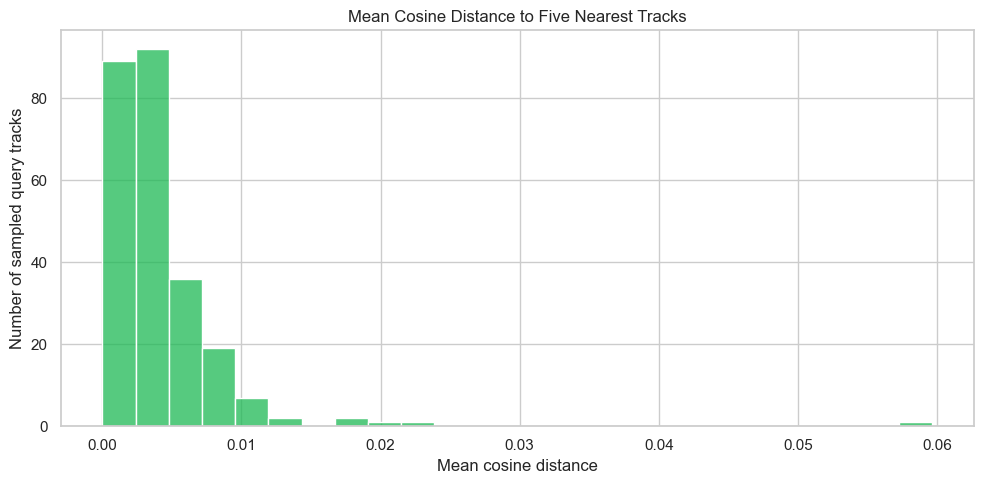

In [10]:
# Reproducible distribution of mean neighbor distances for sampled queries
rng = np.random.default_rng(42)
query_positions = rng.choice(len(df), size=min(250, len(df)), replace=False)
sample_mean_distances = []
for position in query_positions:
    distances, _ = model_knn.kneighbors(
        df_features_scaled[position].reshape(1, -1), n_neighbors=6
    )
    sample_mean_distances.append(distances.flatten()[1:].mean())

plt.figure(figsize=(10, 5))
sns.histplot(sample_mean_distances, bins=25, color='#1DB954', edgecolor='white')
plt.title('Mean Cosine Distance to Five Nearest Tracks')
plt.xlabel('Mean cosine distance')
plt.ylabel('Number of sampled query tracks')
plt.tight_layout()
plt.show()


## Findings and limitations

- The executed dataset contains 89,740 unique tracks after deduplication and required-field filtering.
- The popularity distribution has a long tail, so the baseline can overexpose already popular music.
- Energy and loudness have a strong positive correlation of about 0.76 in the executed analysis.
- For the example query `Comedy`, KNN returns tracks from several genres, showing that audio similarity can cross genre labels.
- The notebook cannot measure individual relevance, rating-prediction error, listening time, retention, or causal business impact because no authentic user interaction history is available.

Future work should collect consented plays, skips, saves, completion events, and timestamps. A collaborative or hybrid model should be introduced only after a user-aware or time-aware split supports held-out evaluation with metrics such as Precision at K, Recall at K, NDCG at K, coverage, novelty, and diversity.
